# Which bus routes should keep running during a fuel shortage?
Budgeted route selection on Colombo's bus–train network (graph theory). Run all cells to reproduce the results and figures in the report.

*Data from public sources; route status not fully verified. See README for limitations.*

In [1]:
# ============================================================
# Which bus routes should be kept running during a fuel shortage?
# FINAL ANALYSIS (data v2): Colombo metropolitan area (south-east, centre, north, west).
# Sources: Wikipedia town pages (Nugegoda, Maharagama, Homagama, Rukmale,
# Godagama, Battaramulla), Dept. of Immigration directions page,
# Sri Lanka Parliament Q&A (routes 103, 117, 144, 192),
# Lanka Metro Transit announcement (CM routes, Aug 2026).
# NOTE: route status (still running or not) is NOT fully verified.
# Route 123 (reported discontinued, Sunday Observer 2022) and CM06 (no stop list published) are excluded.
# ============================================================
import itertools, random, os
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
# ---------- 1. DATA ----------
bus_routes = {
    # --- south-east corridor (v1) ---
    "138":     ["Homagama","Kottawa","Maharagama","Nugegoda","Kirulapana","Thummulla","SlaveIsland","Fort","Pettah"],
    "183":     ["Nugegoda","Kalubowila","Dehiwala","Moratuwa","Panadura"],
    "212/341": ["Nugegoda","Maharagama","Pannipitiya","Erawwala","Makuludoowa","Bokundara"],
    "992":     ["Nugegoda","Maharagama","Pannipitiya","Athurugiriya"],
    "119":     ["Nugegoda","JubileePost","Embuldeniya","Maharagama"],
    "689":     ["Nugegoda","Udahamulla","Madiwela","Thalawathugoda","Hokandara"],
    "690":     ["Nugegoda","JubileePost","Embuldeniya","Madiwela","Kimbulawala","JayawardenepuraHospital"],
    "163":     ["Dehiwala","Nugegoda","Pagoda","Kotte","Battaramulla"],
    "313":     ["Homagama","Kottawa","Maharagama","Kohuwala","Kalubowila"],
    "308":     ["Maharagama","Niyandagala","Kottawa","Homagama"],
    "128/1":   ["Maharagama","Homagama","Munamalewatta"],
    "124":     ["Maharagama","Godagama","Homagama","IhalaBope"],
    "376":     ["Kottawa","Rukmale","Malabe"],
    # --- centre / east / west (v2) ---
    "171":     ["Pelawatta","Battaramulla","Rajagiriya","Borella","Fort"],
    "170":     ["Athurugiriya","Battaramulla","Borella","TownHall","Pettah"],
    "190":     ["Meegoda","Godagama","Battaramulla","Borella","TownHall","Pettah"],
    "174":     ["Kottawa","Thalawathugoda","Battaramulla","Borella"],
    "177":     ["Kaduwela","Battaramulla","Borella","Kollupitiya"],
    "17":      ["Panadura","Moratuwa","Ratmalana","Dehiwala","Nugegoda","Kotte","Battaramulla"],
    "103":     ["Borella","Narahenpita"],
    "144":     ["Rajagiriya","Fort"],
    "117":     ["Nugegoda","Pepiliyana","Attidiya","Ratmalana"],
    "192":     ["Moratuwa","Maharagama"],
    "Mhg-Dehiwala": ["Maharagama","Boralesgamuwa","Bellanwila","Dehiwala"],
    "Mhg-Ratmalana":["Maharagama","Borupana","Ratmalana"],
    # --- Metro Bus (Lanka Metro Transit, Aug 2026): express, endpoints only ---
    "CM01":    ["Makumbura","Pettah","Fort"],
    "CM02":    ["MillenniumCity","Fort"],
    "CM03":    ["Kadawatha","Makumbura"],
    "CM04":    ["Dematagoda","Panadura"],
    "CM05":    ["Battaramulla","Ekala"],
    "CM08":    ["Kesbewa","Pettah"],
}
# Trains keep running during the fuel crisis, so they are always available.
train_routes = {
    "Train-Coastal": ["Fort","Kollupitiya","Bambalapitiya","Wellawatte","Dehiwala","MtLavinia","Ratmalana","Moratuwa","Panadura"],
    "Train-KV":      ["Fort","Nugegoda","Pangiriwatte","Nawinna","Maharagama"],
    "Train-Main":    ["Fort","Maradana","Dematagoda","Kelaniya","Ragama"],
}


# Approximate stop positions (lat, lon) - used ONLY for drawing the map.
coords = {
"Athurugiriya":(6.874,79.998),"Attidiya":(6.8225,79.886),"Bambalapitiya":(6.8905,79.855),
"Battaramulla":(6.900,79.918),"Bellanwila":(6.831,79.889),"Bokundara":(6.823,79.915),
"Boralesgamuwa":(6.840,79.902),"Borella":(6.915,79.878),"Borupana":(6.817,79.892),
"Dehiwala":(6.851,79.865),"Dematagoda":(6.939,79.878),"Ekala":(7.095,79.925),
"Embuldeniya":(6.862,79.905),"Erawwala":(6.832,79.933),"Fort":(6.934,79.850),
"Godagama":(6.848,79.993),"Hokandara":(6.873,79.957),"Homagama":(6.843,80.003),
"IhalaBope":(6.815,80.038),"JayawardenepuraHospital":(6.868,79.912),"JubileePost":(6.867,79.894),
"Kadawatha":(7.001,79.957),"Kaduwela":(6.933,79.986),"Kalubowila":(6.862,79.880),
"Kelaniya":(6.955,79.922),"Kesbewa":(6.794,79.939),"Kimbulawala":(6.878,79.925),
"Kirulapana":(6.883,79.878),"Kohuwala":(6.858,79.889),"Kollupitiya":(6.911,79.850),
"Kottawa":(6.841,79.964),"Kotte":(6.891,79.908),"Madiwela":(6.879,79.918),
"Maharagama":(6.848,79.927),"Makuludoowa":(6.830,79.919),"Makumbura":(6.852,79.974),
"Malabe":(6.904,79.957),"Maradana":(6.929,79.865),"Meegoda":(6.840,80.050),
"MillenniumCity":(6.885,80.005),"Moratuwa":(6.773,79.882),"MtLavinia":(6.838,79.863),
"Munamalewatta":(6.805,80.000),"Narahenpita":(6.894,79.877),"Nawinna":(6.853,79.906),
"Niyandagala":(6.820,79.965),"Nugegoda":(6.864,79.899),"Pagoda":(6.878,79.902),
"Panadura":(6.713,79.907),"Pangiriwatte":(6.859,79.902),"Pannipitiya":(6.847,79.946),
"Pelawatta":(6.890,79.925),"Pepiliyana":(6.845,79.893),"Pettah":(6.9355,79.8528),
"Ragama":(7.028,79.920),"Rajagiriya":(6.910,79.894),"Ratmalana":(6.820,79.880),
"Rukmale":(6.857,79.986),"SlaveIsland":(6.925,79.853),"Thalawathugoda":(6.872,79.935),
"Thummulla":(6.909,79.862),"TownHall":(6.914,79.861),"Udahamulla":(6.878,79.912),
"Wellawatte":(6.874,79.860),
}

In [3]:
# ---------- 2. FUNCTIONS ----------
def make_tools(bus_routes, train_routes):
    all_routes = {**bus_routes, **train_routes}
    all_stops = sorted({s for r in all_routes.values() for s in r})
    train_names, bus_names = list(train_routes), list(bus_routes)

    def build_graph(names):
        G = nx.Graph(); G.add_nodes_from(all_stops)
        for nme in names:
            st = all_routes[nme]
            for a, b in zip(st, st[1:]):
                if a != b: G.add_edge(a, b)
        return G

    def connectivity(G):
        n = G.number_of_nodes()
        return sum(len(c)*(len(c)-1) for c in nx.connected_components(G)) / (n*(n-1))

    def score(kept):
        return connectivity(build_graph(train_names + list(kept)))
    return all_routes, all_stops, train_names, bus_names, build_graph, connectivity, score

def greedy_curve(bus_names, score):
    kept, curve, rem = [], [(0, score([]), [])], list(bus_names)
    for k in range(1, len(bus_names)+1):
        r = max(rem, key=lambda x: score(kept+[x])); kept.append(r); rem.remove(r)
        curve.append((k, score(kept), list(kept)))
    return curve

def swap_improve(start, bus_names, score):
    """Local search: swap one kept route with one dropped route while it helps."""
    cur, cur_s = list(start), score(start)
    improved = True
    while improved:
        improved = False
        for a in list(cur):
            for b in [x for x in bus_names if x not in cur]:
                trial = [x for x in cur if x != a] + [b]
                s = score(trial)
                if s > cur_s + 1e-12:
                    cur, cur_s, improved = trial, s, True
                    break
            if improved: break
    return cur_s, cur

def run_all(bus_routes, train_routes, trials=300, seed=1):
    random.seed(seed)
    all_routes, all_stops, train_names, bus_names, build_graph, connectivity, score = make_tools(bus_routes, train_routes)
    N = len(bus_names)
    gc = greedy_curve(bus_names, score)
    res = {"k":[], "rand_mean":[], "rand_lo":[], "rand_hi":[], "longest":[], "greedy":[], "swap":[], "swap_sets":[]}
    for k in range(N+1):
        if k == 0:
            s0 = score([]); vals = [s0]
        else:
            vals = sorted(score(random.sample(bus_names, k)) for _ in range(trials))
        res["k"].append(k)
        res["rand_mean"].append(sum(vals)/len(vals))
        res["rand_lo"].append(vals[int(0.1*(len(vals)-1))]); res["rand_hi"].append(vals[int(0.9*(len(vals)-1))])
        top = sorted(bus_names, key=lambda r: len(set(bus_routes[r])), reverse=True)[:k]
        res["longest"].append(score(top))
        res["greedy"].append(gc[k][1])
        s, st = swap_improve(gc[k][2], bus_names, score) if 0 < k < N else (gc[k][1], gc[k][2])
        res["swap"].append(s); res["swap_sets"].append(st)
    # centrality-first baseline: keep the routes whose stops have the highest total betweenness
    btw_all = nx.betweenness_centrality(build_graph(train_names + bus_names))
    rank = sorted(bus_names, key=lambda x: sum(btw_all[s] for s in set(bus_routes[x])), reverse=True)
    res["central"] = [score(rank[:k]) for k in range(N+1)]
    return res, gc, (all_routes, all_stops, train_names, bus_names, build_graph, connectivity, score)

def auc(xs, ys):
    return sum((xs[i+1]-xs[i])*(ys[i]+ys[i+1])/2 for i in range(len(xs)-1)) / (xs[-1]-xs[0])

In [4]:
# ---------- 3. MAIN ANALYSIS ----------
res, gc, T = run_all(bus_routes, train_routes)
all_routes, all_stops, train_names, bus_names, build_graph, connectivity, score = T
N = len(bus_names)
pct = [k/N*100 for k in res["k"]]

# 3a. robustness check: remove express "CM" routes (endpoints-only data)
bus_noCM = {k: v for k, v in bus_routes.items() if not k.startswith("CM")}
res2, gc2, T2 = run_all(bus_noCM, train_routes)
N2 = len(bus_noCM)

# 3b. which routes are individually critical? (drop one route from the full bus set)
full = score(bus_names)
drop_one = {r: full - score([x for x in bus_names if x != r]) for r in bus_names}

# 3c. most central stops in the full network
Gfull = build_graph(train_names + bus_names)
btw = nx.betweenness_centrality(Gfull)
deg = dict(Gfull.degree())
top_btw = sorted(btw.items(), key=lambda kv: -kv[1])[:10]

# 3d. summary numbers
def at(res, N, frac):
    k = round(frac*N); return k, res["rand_mean"][k], res["longest"][k], res["greedy"][k], res["swap"][k]
print(f"Stops={len(all_stops)} BusRoutes={N} TrainLines={len(train_names)} GraphEdges={Gfull.number_of_edges()}")
print("Train-only connectivity:", round(res['greedy'][0],4))
for f in (0.25, 0.5, 0.75):
    k, r, l, g, s = at(res, N, f)
    print(f"Budget {int(f*100)}% (k={k}): random={r:.3f} longest={l:.3f} greedy={g:.3f} greedy+swap={s:.3f}")
print("Greedy first reaches 1.0 at k =", next(k for k,g in zip(res['k'],res['greedy']) if g>=0.9999))
print("Greedy+swap first reaches 1.0 at k =", next(k for k,g in zip(res['k'],res['swap']) if g>=0.9999))
print("AUC random/longest/greedy/swap:", [round(auc(pct, res[m]),3) for m in ("rand_mean","longest","greedy","swap")])
print("Order greedy picks routes:", gc[-1][2])
print("Routes dropped first (greedy order reversed tail):", gc[-1][2][::-1][:10])
print("Drop-one loss (top):", sorted(drop_one.items(), key=lambda kv:-kv[1])[:8])
print("Top betweenness:", [(s, round(b,3), deg[s]) for s,b in top_btw])
print("--- Robustness (no CM routes): N=", N2)
for f in (0.25, 0.5, 0.75):
    k, r, l, g, s = at(res2, N2, f)
    print(f"Budget {int(f*100)}% (k={k}): random={r:.3f} longest={l:.3f} greedy={g:.3f} greedy+swap={s:.3f}")
print("Greedy no-CM reaches 1.0 at k =", next(k for k,g in zip(res2['k'],res2['greedy']) if g>=0.9999), "of", N2)
print("AUC no-CM random/longest/greedy/swap:", [round(auc([k/N2*100 for k in res2['k']], res2[m]),3) for m in ("rand_mean","longest","greedy","swap")])
K50 = round(0.5*N)
kept50 = res["swap_sets"][K50]
print("Kept at 50% (greedy+swap):", sorted(kept50)); print("Dropped at 50%:", sorted(set(bus_names)-set(kept50)))

Stops=64 BusRoutes=31 TrainLines=3 GraphEdges=90
Train-only connectivity: 0.0675
Budget 25% (k=8): random=0.265 longest=0.448 greedy=0.513 greedy+swap=0.513
Budget 50% (k=16): random=0.515 longest=0.583 greedy=0.792 greedy+swap=0.792
Budget 75% (k=23): random=0.739 longest=0.849 greedy=1.000 greedy+swap=1.000
Greedy first reaches 1.0 at k = 23
Greedy+swap first reaches 1.0 at k = 23
AUC random/longest/greedy/swap: [0.508, 0.605, 0.713, 0.713]
Order greedy picks routes: ['138', '690', '190', '212/341', '689', '163', '313', '376', '171', '117', 'Mhg-Dehiwala', '992', '308', '128/1', '124', '177', '103', 'Mhg-Ratmalana', 'CM01', 'CM02', 'CM03', 'CM05', 'CM08', '183', '119', '170', '174', '17', '144', '192', 'CM04']
Routes dropped first (greedy order reversed tail): ['CM04', '192', '144', '17', '174', '170', '119', '183', 'CM08', 'CM05']
Drop-one loss (top): [('138', 0.09226190476190477), ('212/341', 0.09226190476190477), ('689', 0.062003968253968256), ('690', 0.062003968253968256), ('376'

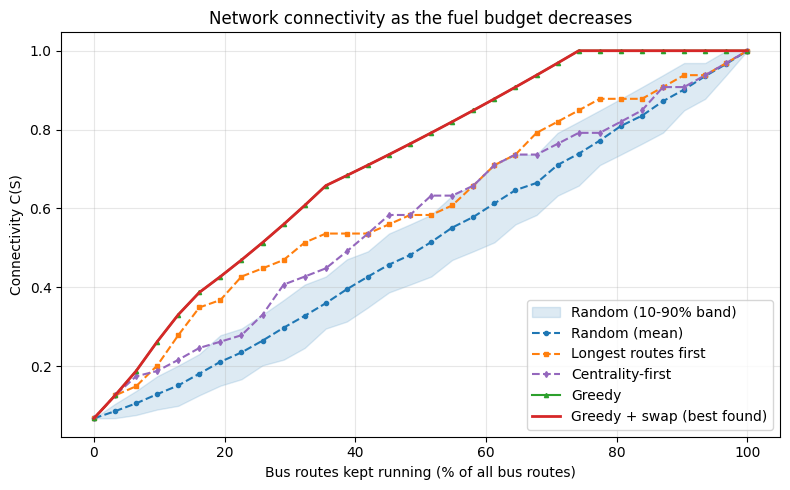

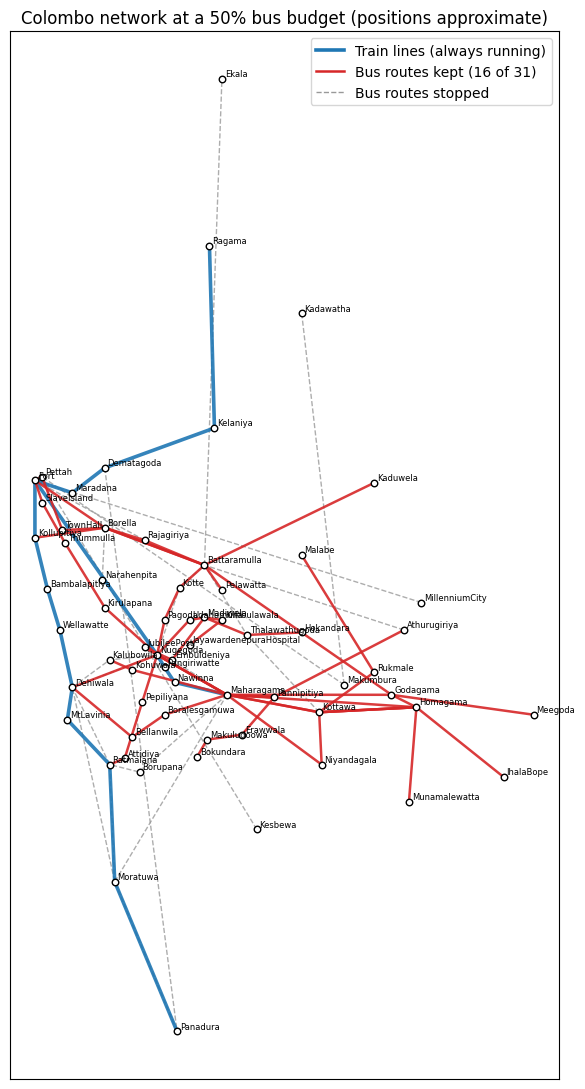

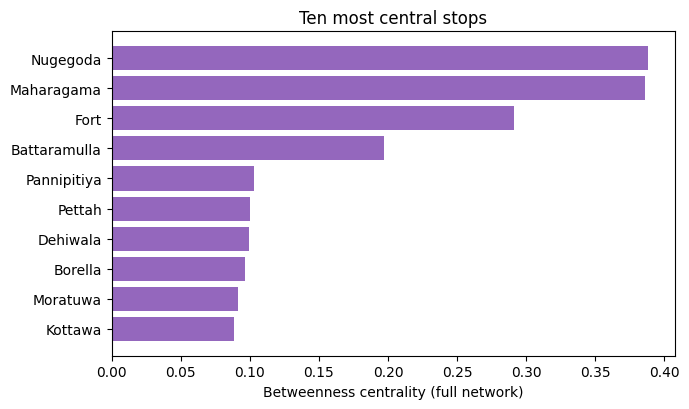

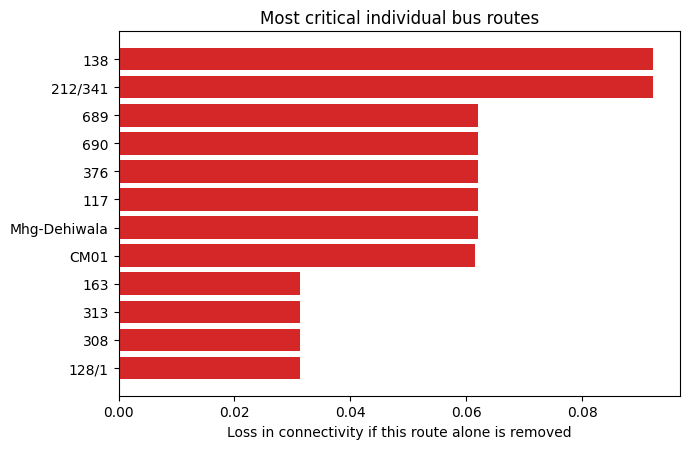

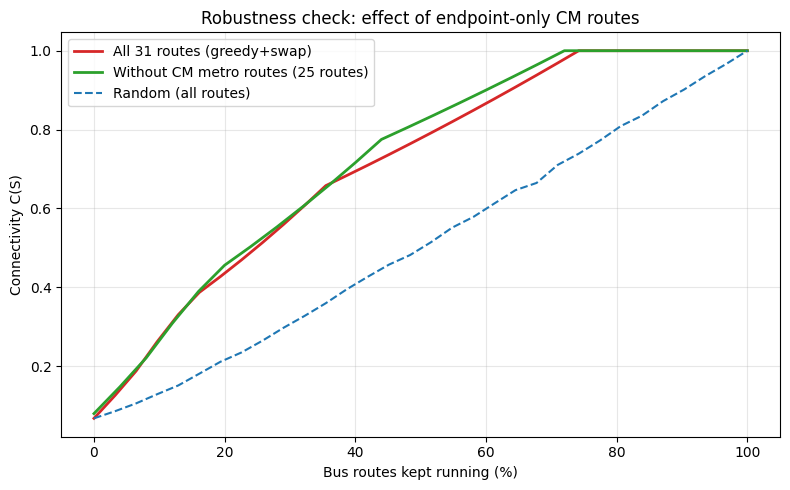

figures saved


In [5]:
# ---------- 4. FIGURES ----------
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"font.size": 10})
# Fig 1: connectivity vs budget
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(pct, res["rand_lo"], res["rand_hi"], color="tab:blue", alpha=0.15, label="Random (10-90% band)")
ax.plot(pct, res["rand_mean"], "o--", ms=3, color="tab:blue", label="Random (mean)")
ax.plot(pct, res["longest"], "s--", ms=3, color="tab:orange", label="Longest routes first")
ax.plot(pct, res["central"], "d--", ms=3, color="tab:purple", label="Centrality-first")
ax.plot(pct, res["greedy"], "^-", ms=3, color="tab:green", label="Greedy")
ax.plot(pct, res["swap"], "-", lw=2, color="tab:red", label="Greedy + swap (best found)")
ax.set_xlabel("Bus routes kept running (% of all bus routes)"); ax.set_ylabel("Connectivity C(S)")
ax.set_title("Network connectivity as the fuel budget decreases"); ax.grid(alpha=0.3); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig("figures/fig1_connectivity.png", dpi=170); plt.show()

# Fig 2: map of kept vs dropped routes at 50%
def draw_routes(ax, names, color, lw, alpha, ls="-"):
    for nme in names:
        st = [s for s in all_routes[nme]]
        xs = [coords[s][1] for s in st]; ys = [coords[s][0] for s in st]
        ax.plot(xs, ys, color=color, lw=lw, alpha=alpha, ls=ls, zorder=2)
fig, ax = plt.subplots(figsize=(9, 11))
draw_routes(ax, [r for r in bus_names if r not in kept50], "0.6", 1.0, 0.8, "--")
draw_routes(ax, train_names, "tab:blue", 2.6, 0.9)
draw_routes(ax, kept50, "tab:red", 1.8, 0.9)
for s,(la,lo) in coords.items():
    ax.scatter(lo, la, s=22, color="white", edgecolor="black", zorder=3)
    ax.annotate(s, (lo, la), fontsize=6, xytext=(2,2), textcoords="offset points", zorder=4)
ax.plot([],[],color="tab:blue",lw=2.6,label="Train lines (always running)")
ax.plot([],[],color="tab:red",lw=1.8,label=f"Bus routes kept ({K50} of {N})")
ax.plot([],[],color="0.6",lw=1,ls="--",label="Bus routes stopped")
ax.set_title("Colombo network at a 50% bus budget (positions approximate)")
ax.legend(loc="upper right"); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect(1.0)
fig.tight_layout(); fig.savefig("figures/fig2_map_50pct.png", dpi=170); plt.show()

# Fig 3: top stops by betweenness
fig, ax = plt.subplots(figsize=(7, 4.2))
names = [s for s,_ in top_btw][::-1]; vals = [b for _,b in top_btw][::-1]
ax.barh(names, vals, color="tab:purple"); ax.set_xlabel("Betweenness centrality (full network)")
ax.set_title("Ten most central stops"); fig.tight_layout(); fig.savefig("figures/fig3_centrality.png", dpi=170); plt.show()

# Fig 4: drop-one route criticality
items = sorted(drop_one.items(), key=lambda kv: -kv[1])[:12][::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh([k for k,_ in items], [v for _,v in items], color="tab:red")
ax.set_xlabel("Loss in connectivity if this route alone is removed")
ax.set_title("Most critical individual bus routes"); fig.tight_layout(); fig.savefig("figures/fig4_critical_routes.png", dpi=170); plt.show()

# Fig 5: robustness (with vs without CM routes)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pct, res["swap"], "-", lw=2, color="tab:red", label=f"All {N} routes (greedy+swap)")
ax.plot([k/N2*100 for k in res2["k"]], res2["swap"], "-", lw=2, color="tab:green", label=f"Without CM metro routes ({N2} routes)")
ax.plot(pct, res["rand_mean"], "--", color="tab:blue", label="Random (all routes)")
ax.set_xlabel("Bus routes kept running (%)"); ax.set_ylabel("Connectivity C(S)")
ax.set_title("Robustness check: effect of endpoint-only CM routes"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig("figures/fig5_robustness.png", dpi=170); plt.show()
print("figures saved")